<a href="https://colab.research.google.com/github/Gomesh-code/Traffic_Sign_Detection/blob/main/Traffic_Sign_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🚦 Traffic Sign Detection and Recognition with Python (PyTorch + OpenCV)

**Platform:** Google Colab (set *Runtime → Change runtime type → T4 GPU* for faster training)
**Dataset:** [GTSRB – German Traffic Sign Recognition Benchmark](https://benchmark.ini.rub.de/) (43 classes, ~39,000 labelled images). It is downloaded automatically through `torchvision.datasets.GTSRB`, so nothing needs to be uploaded.

## Project overview
The system is a two-stage pipeline:

1. **Recognition model** – a CNN with batch normalisation trained on GTSRB crops (43 sign classes + 1 *background* class used to reject non-sign regions).
2. **Detection stage** – colour-based region proposals (HSV segmentation for red and blue sign borders → morphology → contours → geometric filters), followed by CNN classification of every proposal, confidence thresholding and Non-Maximum Suppression (NMS).

Because GTSRB itself contains only cropped signs, the detector is evaluated on **synthetic road scenes** generated by pasting test-set signs onto cluttered backgrounds. Ground-truth boxes are therefore known exactly, which lets us compute detection precision / recall.

### Notebook outline
1. Setup and imports
2. Dataset download and loading
3. Exploratory data analysis
4. Background class + train/validation split + augmentation
5. CNN architecture
6. Training
7. Evaluation (accuracy, classification report, confusion matrix)
8. Detection pipeline (proposals → classification → NMS)
9. Synthetic scene evaluation (precision / recall)
10. Try it on your own image
11. Save and download the model
12. Limitations and extensions (YOLOv8)

## 1. Setup and imports

In [ ]:
import os, random, time, copy
import numpy as np
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import transforms
from torchvision.datasets import GTSRB
from torchvision.ops import nms, box_iou

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch :", torch.__version__)
print("OpenCV  :", cv2.__version__)
print("Device  :", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU (enable GPU for faster training)")

PyTorch : 2.11.0+cu130
OpenCV  : 4.14.0
Device  : cuda | Tesla T4


In [ ]:
IMG_SIZE = 48          # all crops are resized to 48x48 before entering the CNN
NUM_SIGN_CLASSES = 43
BG_CLASS = 43          # extra 'background / not a sign' class
NUM_CLASSES = 44

CLASS_NAMES = [
    "Speed limit (20km/h)", "Speed limit (30km/h)", "Speed limit (50km/h)", "Speed limit (60km/h)",
    "Speed limit (70km/h)", "Speed limit (80km/h)", "End of speed limit (80km/h)", "Speed limit (100km/h)",
    "Speed limit (120km/h)", "No passing", "No passing for vehicles over 3.5t", "Right-of-way at next intersection",
    "Priority road", "Yield", "Stop", "No vehicles", "Vehicles over 3.5t prohibited", "No entry",
    "General caution", "Dangerous curve left", "Dangerous curve right", "Double curve", "Bumpy road",
    "Slippery road", "Road narrows on the right", "Road work", "Traffic signals", "Pedestrians",
    "Children crossing", "Bicycles crossing", "Beware of ice/snow", "Wild animals crossing",
    "End of all speed and passing limits", "Turn right ahead", "Turn left ahead", "Ahead only",
    "Go straight or right", "Go straight or left", "Keep right", "Keep left", "Roundabout mandatory",
    "End of no passing", "End of no passing by vehicles over 3.5t", "Background (no sign)"
]
assert len(CLASS_NAMES) == NUM_CLASSES

## 2. Dataset download and loading
`torchvision.datasets.GTSRB` downloads the official train (26,640 images) and test (12,630 images) splits (≈ 300 MB) into `./data`. The first run takes a minute or two.

For fast training we decode every image once, resize it to 48×48 and keep it in RAM as a PIL image.

In [ ]:
DATA_ROOT = "./data"

def load_gtsrb(split):
    ds = GTSRB(root=DATA_ROOT, split=split, download=True)
    imgs, labels = [], []
    for img, label in ds:
        imgs.append(img.convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR))
        labels.append(int(label))
    return ds, imgs, np.array(labels)

t0 = time.time()
raw_train, train_imgs, train_labels = load_gtsrb("train")
raw_test,  test_imgs,  test_labels  = load_gtsrb("test")
print(f"Train images: {len(train_imgs)} | Test images: {len(test_imgs)} | loaded in {time.time()-t0:.1f}s")
print("Label range  :", train_labels.min(), "to", train_labels.max())

100%|██████████| 187M/187M [00:11<00:00, 16.6MB/s]
100%|██████████| 89.0M/89.0M [00:06<00:00, 13.3MB/s]
100%|██████████| 99.6k/99.6k [00:00<00:00, 209kB/s]


Train images: 26640 | Test images: 12630 | loaded in 37.5s
Label range  : 0 to 42


## 3. Exploratory data analysis

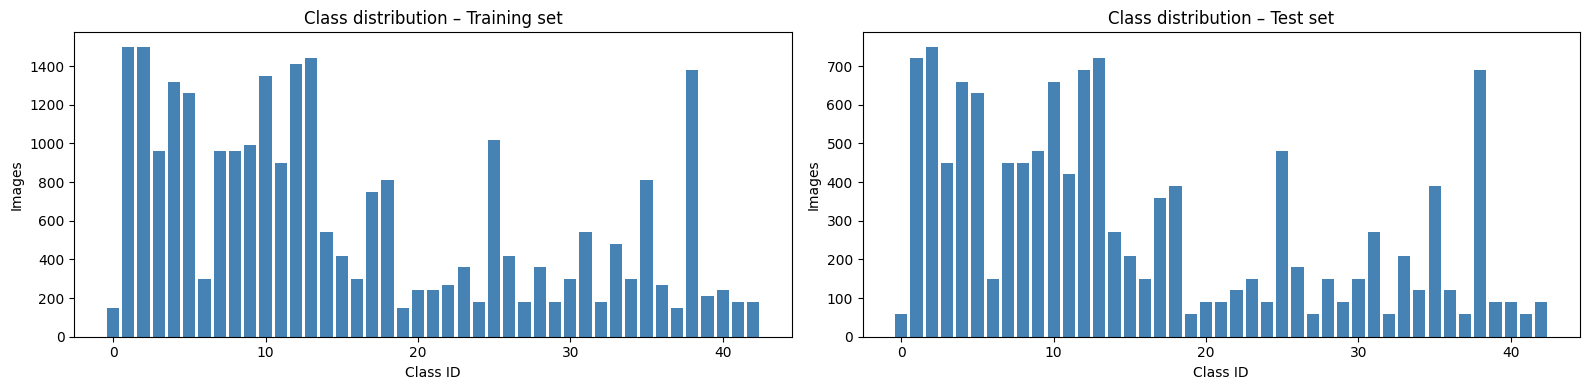

Most frequent : class 1 (Speed limit (30km/h)) – 1500 images
Least frequent: class 0 (Speed limit (20km/h)) – 150 images
Imbalance ratio: 10.0x


In [ ]:
# Class distribution
fig, ax = plt.subplots(1, 2, figsize=(16, 4))
for a, lab, title in zip(ax, [train_labels, test_labels], ["Training set", "Test set"]):
    counts = np.bincount(lab, minlength=NUM_SIGN_CLASSES)
    a.bar(range(NUM_SIGN_CLASSES), counts, color="steelblue")
    a.set_title(f"Class distribution – {title}")
    a.set_xlabel("Class ID"); a.set_ylabel("Images")
plt.tight_layout(); plt.show()

counts = np.bincount(train_labels, minlength=NUM_SIGN_CLASSES)
print(f"Most frequent : class {counts.argmax()} ({CLASS_NAMES[counts.argmax()]}) – {counts.max()} images")
print(f"Least frequent: class {counts.argmin()} ({CLASS_NAMES[counts.argmin()]}) – {counts.min()} images")
print(f"Imbalance ratio: {counts.max()/counts.min():.1f}x")

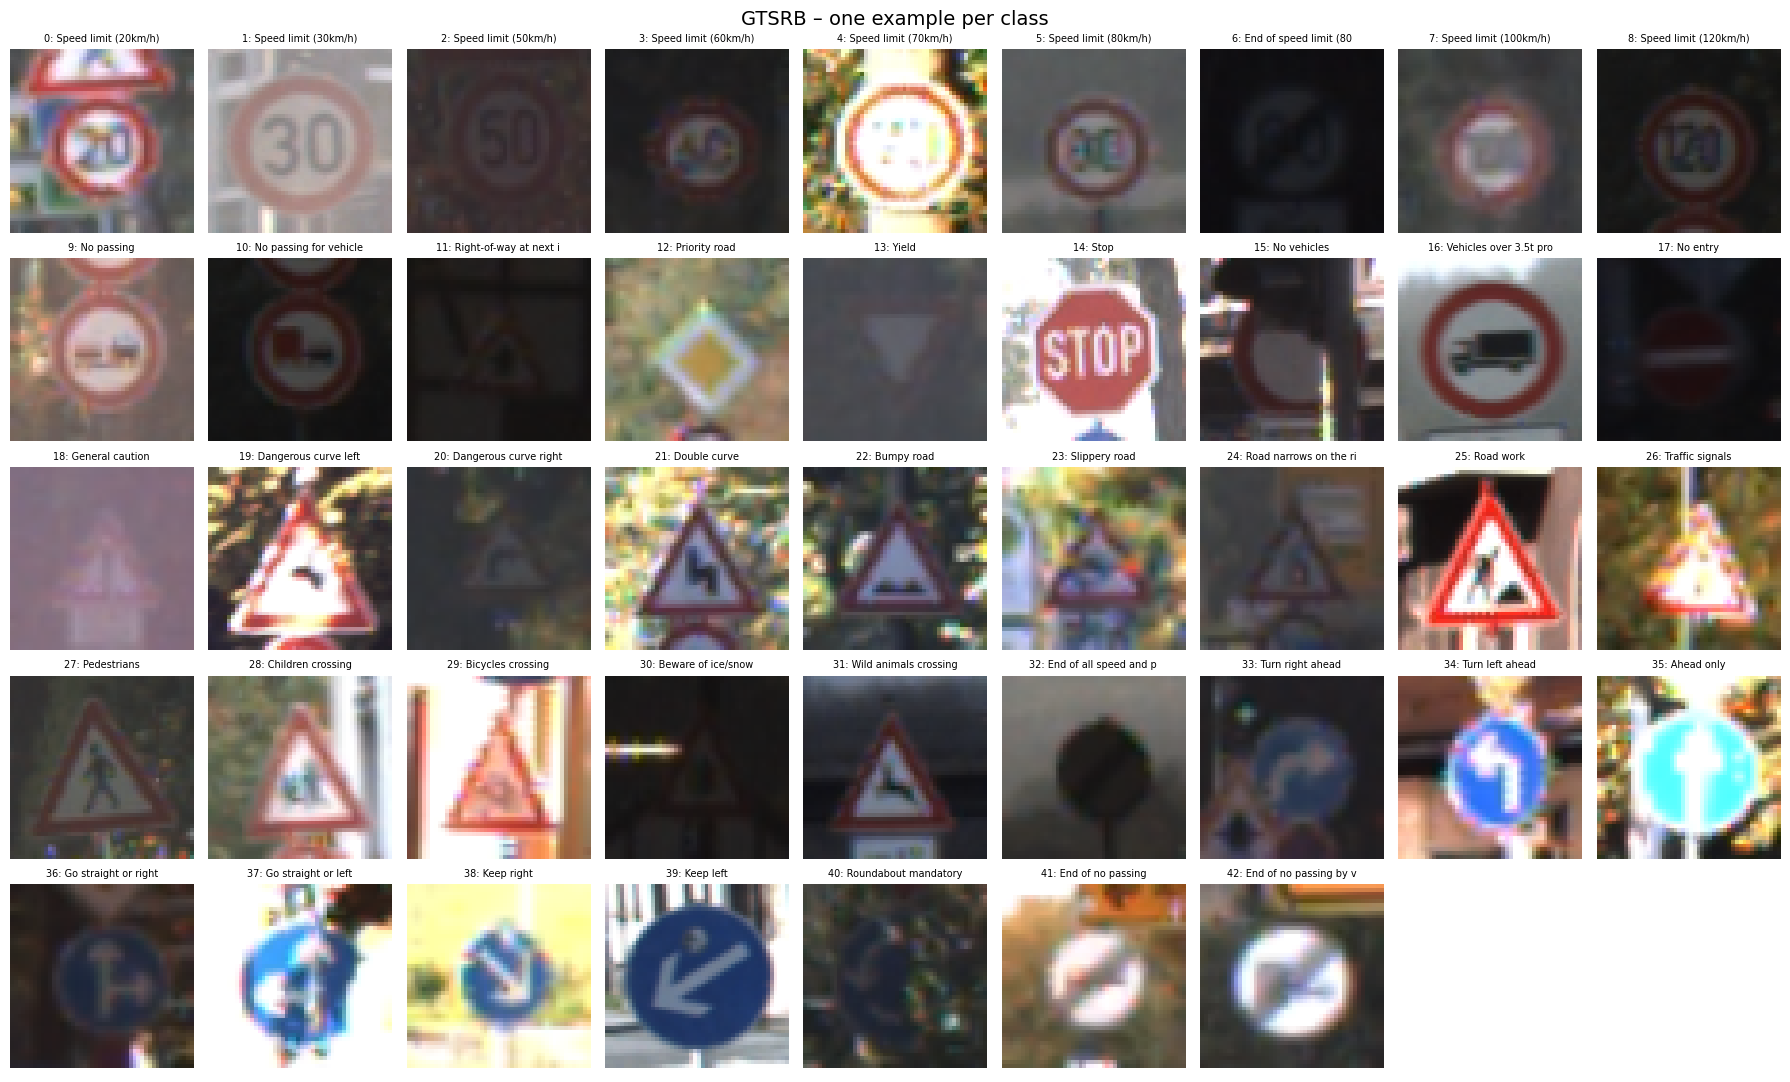

In [ ]:
# One sample per class
fig, axes = plt.subplots(5, 9, figsize=(18, 11))
for c, ax in enumerate(axes.ravel()):
    ax.axis("off")
    if c < NUM_SIGN_CLASSES:
        idx = np.where(train_labels == c)[0][0]
        ax.imshow(train_imgs[idx])
        ax.set_title(f"{c}: {CLASS_NAMES[c][:22]}", fontsize=7)
plt.suptitle("GTSRB – one example per class", fontsize=14)
plt.tight_layout(); plt.show()

## 4. Background class, train/validation split and augmentation

**Why a background class?** A plain 43-way classifier must label *every* region as some sign. In a detector, most proposals are not signs (red cars, blue sky patches, billboards), so we synthesise cluttered backgrounds – including red/blue distractor blobs – and add random crops of them as class 43. The network then learns to reject false proposals.

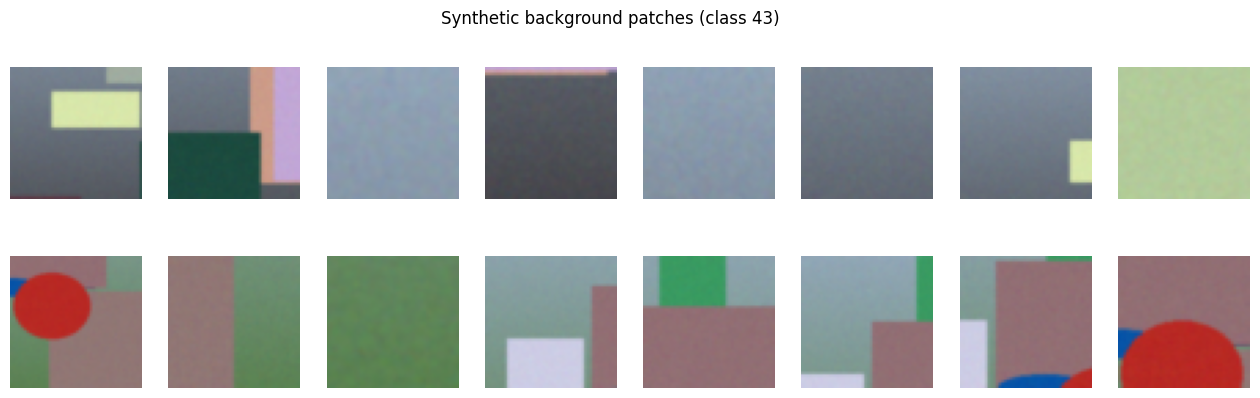

In [ ]:
BG_PALETTE = [(120, 120, 120), (90, 130, 80), (190, 180, 150), (150, 170, 190),
              (70, 70, 75), (170, 160, 140), (60, 100, 60), (200, 200, 200)]

def make_background(h, w, rng, distractors=True):
    """Synthetic street-like background: gradient + muted rectangles + optional red/blue distractors."""
    c1 = np.array(BG_PALETTE[rng.integers(len(BG_PALETTE))], dtype=np.float32)
    c2 = np.array(BG_PALETTE[rng.integers(len(BG_PALETTE))], dtype=np.float32)
    t = np.linspace(0, 1, h, dtype=np.float32)[:, None, None]
    img = (c1 * (1 - t) + c2 * t) * np.ones((h, w, 3), np.float32)
    for _ in range(rng.integers(6, 14)):           # buildings / road markings / trees
        x0, y0 = rng.integers(0, w - 20), rng.integers(0, h - 20)
        x1, y1 = min(w, x0 + rng.integers(20, 160)), min(h, y0 + rng.integers(20, 160))
        col = np.array(BG_PALETTE[rng.integers(len(BG_PALETTE))]) + rng.integers(-35, 35, 3)
        img[y0:y1, x0:x1] = np.clip(col, 0, 255)
    img = img.astype(np.uint8)
    if distractors and rng.random() < 0.6:         # red / blue blobs that are NOT signs
        for _ in range(rng.integers(1, 4)):
            col = (int(rng.integers(150, 255)), int(rng.integers(0, 60)), int(rng.integers(0, 60))) if rng.random() < 0.5 \
                  else (int(rng.integers(0, 50)), int(rng.integers(30, 100)), int(rng.integers(150, 255)))
            x, y = int(rng.integers(0, w - 90)), int(rng.integers(0, h - 90))
            sw, sh = int(rng.integers(25, 90)), int(rng.integers(15, 90))
            if rng.random() < 0.5:
                cv2.rectangle(img, (x, y), (x + sw, y + sh), col, -1)
            else:
                cv2.ellipse(img, (x + sw // 2, y + sh // 2), (sw // 2, sh // 2), 0, 0, 360, col, -1)
    noise = rng.normal(0, 6, img.shape)
    img = np.clip(img.astype(np.float32) + noise, 0, 255).astype(np.uint8)
    return cv2.GaussianBlur(img, (3, 3), 0)

def make_bg_patches(n, seed):
    rng = np.random.default_rng(seed)
    patches = []
    while len(patches) < n:
        bg = make_background(300, 400, rng)
        for _ in range(8):
            s = int(rng.integers(40, 150))
            x, y = int(rng.integers(0, 400 - s)), int(rng.integers(0, 300 - s))
            patch = bg[y:y + s, x:x + s]
            patches.append(Image.fromarray(patch).resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR))
    return patches[:n]

bg_train_imgs = make_bg_patches(1500, seed=1)
bg_test_imgs  = make_bg_patches(400,  seed=2)

fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax, im in zip(axes.ravel(), bg_train_imgs[:16]):
    ax.imshow(im); ax.axis("off")
plt.suptitle("Synthetic background patches (class 43)"); plt.show()

In [ ]:
# Combine sign images with background patches
all_train_imgs   = train_imgs + bg_train_imgs
all_train_labels = np.concatenate([train_labels, np.full(len(bg_train_imgs), BG_CLASS)])
full_test_imgs   = test_imgs + bg_test_imgs
full_test_labels = np.concatenate([test_labels, np.full(len(bg_test_imgs), BG_CLASS)])

# Stratified 85 / 15 train–validation split
tr_idx, val_idx = train_test_split(np.arange(len(all_train_imgs)), test_size=0.15,
                                   stratify=all_train_labels, random_state=SEED)
print(f"Train: {len(tr_idx)} | Val: {len(val_idx)} | Test: {len(full_test_imgs)}")

MEAN, STD = (0.5, 0.5, 0.5), (0.5, 0.5, 0.5)

# NOTE: no horizontal flips – flipping would turn "turn left" into "turn right".
train_tf = transforms.Compose([
    transforms.RandomAffine(degrees=12, translate=(0.1, 0.1), scale=(0.85, 1.15)),
    transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.3),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class SignDataset(Dataset):
    def __init__(self, imgs, labels, tf):
        self.imgs, self.labels, self.tf = imgs, labels, tf
    def __len__(self): return len(self.imgs)
    def __getitem__(self, i):
        return self.tf(self.imgs[i]), int(self.labels[i])

train_ds = SignDataset([all_train_imgs[i] for i in tr_idx],  all_train_labels[tr_idx],  train_tf)
val_ds   = SignDataset([all_train_imgs[i] for i in val_idx], all_train_labels[val_idx], eval_tf)
test_ds  = SignDataset(full_test_imgs, full_test_labels, eval_tf)

BATCH = 128
train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=256,  shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=256,  shuffle=False, num_workers=2, pin_memory=True)

Train: 23919 | Val: 4221 | Test: 13030


## 5. CNN architecture
Three convolutional blocks (two 3×3 convolutions + BatchNorm + ReLU, then max-pooling and dropout) followed by a fully connected classifier. Channel widths grow 32 → 64 → 128 while the spatial size shrinks 48 → 24 → 12 → 6.

In [ ]:
class SignNet(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()
        def block(cin, cout, p):
            return nn.Sequential(
                nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
                nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
                nn.MaxPool2d(2), nn.Dropout2d(p))
        self.features = nn.Sequential(block(3, 32, 0.1), block(32, 64, 0.15), block(64, 128, 0.2))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 6 * 6, 256), nn.BatchNorm1d(256), nn.ReLU(inplace=True), nn.Dropout(0.4),
            nn.Linear(256, num_classes))
    def forward(self, x):
        return self.classifier(self.features(x))

model = SignNet().to(device)
n_params = sum(p.numel() for p in model.parameters())
print(model)
print(f"\nTrainable parameters: {n_params:,}")

SignNet(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (7): Dropout2d(p=0.1, inplace=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track

## 6. Training
* Loss: cross-entropy with label smoothing (0.05)
* Optimiser: AdamW (weight decay 1e-4) with a One-Cycle learning-rate schedule
* Mixed precision on GPU; the best checkpoint by validation accuracy is kept

In [ ]:
EPOCHS = 15
criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=3e-3, epochs=EPOCHS,
                                                steps_per_epoch=len(train_loader))
use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

def run_epoch(loader, train=False):
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                out = model(x)
                loss = criterion(out, y)
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer); scaler.update(); scheduler.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_acc, best_state = 0.0, None
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    tl, ta = run_epoch(train_loader, train=True)
    vl, va = run_epoch(val_loader, train=False)
    for k, v in zip(history, [tl, vl, ta, va]): history[k].append(v)
    if va > best_acc:
        best_acc, best_state = va, copy.deepcopy(model.state_dict())
    print(f"Epoch {epoch:2d}/{EPOCHS} | train loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f} | {time.time()-t0:.1f}s")

model.load_state_dict(best_state)
print(f"\nBest validation accuracy: {best_acc:.4f}")

Epoch  1/15 | train loss 2.8734 acc 0.2736 | val loss 1.6933 acc 0.5731 | 19.9s
Epoch  2/15 | train loss 1.5050 acc 0.6527 | val loss 0.7385 acc 0.8955 | 16.7s
Epoch  3/15 | train loss 0.8252 acc 0.8935 | val loss 0.5471 acc 0.9855 | 17.1s
Epoch  4/15 | train loss 0.6670 acc 0.9441 | val loss 0.4965 acc 0.9934 | 16.8s
Epoch  5/15 | train loss 0.5860 acc 0.9679 | val loss 0.4707 acc 0.9983 | 16.7s
Epoch  6/15 | train loss 0.5341 acc 0.9818 | val loss 0.4493 acc 0.9998 | 16.5s
Epoch  7/15 | train loss 0.5099 acc 0.9872 | val loss 0.4350 acc 1.0000 | 17.5s
Epoch  8/15 | train loss 0.4864 acc 0.9904 | val loss 0.4218 acc 1.0000 | 16.5s
Epoch  9/15 | train loss 0.4703 acc 0.9943 | val loss 0.4125 acc 0.9998 | 16.5s
Epoch 10/15 | train loss 0.4607 acc 0.9954 | val loss 0.4127 acc 1.0000 | 16.5s
Epoch 11/15 | train loss 0.4531 acc 0.9962 | val loss 0.4087 acc 1.0000 | 17.6s
Epoch 12/15 | train loss 0.4469 acc 0.9969 | val loss 0.4051 acc 1.0000 | 16.6s
Epoch 13/15 | train loss 0.4407 acc 0.99

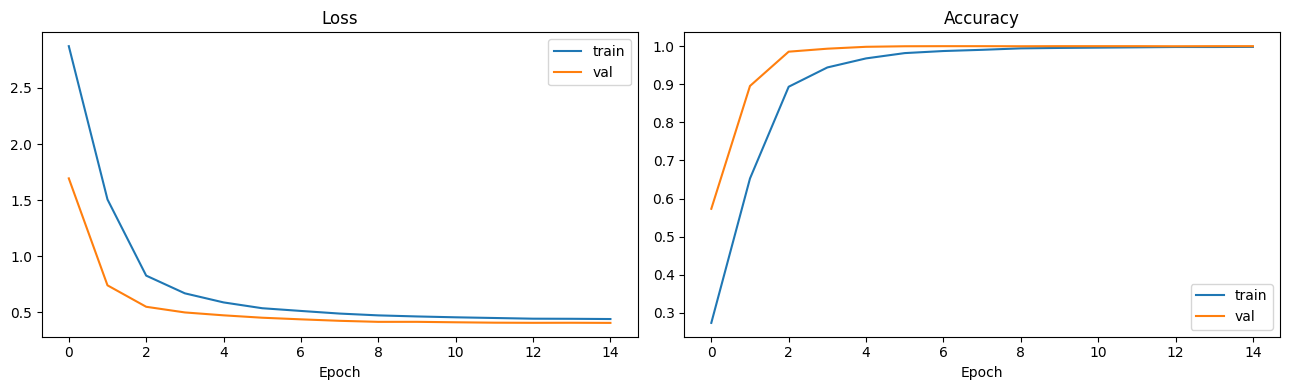

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(history["train_loss"], label="train"); ax[0].plot(history["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(history["train_acc"], label="train"); ax[1].plot(history["val_acc"], label="val")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

## 7. Evaluation on the official GTSRB test set

In [ ]:
@torch.no_grad()
def predict_loader(loader):
    model.eval()
    preds, probs = [], []
    for x, _ in loader:
        p = F.softmax(model(x.to(device)), dim=1).cpu()
        probs.append(p); preds.append(p.argmax(1))
    return torch.cat(preds).numpy(), torch.cat(probs).numpy()

test_preds, test_probs = predict_loader(test_loader)
test_acc = accuracy_score(full_test_labels, test_preds)
sign_mask = full_test_labels != BG_CLASS
sign_acc = accuracy_score(full_test_labels[sign_mask], test_preds[sign_mask])
print(f"Overall test accuracy (44 classes)      : {test_acc*100:.2f}%")
print(f"Accuracy on the 12,630 real sign images : {sign_acc*100:.2f}%")

Overall test accuracy (44 classes)      : 99.45%
Accuracy on the 12,630 real sign images : 99.44%


In [ ]:
print(classification_report(full_test_labels, test_preds, target_names=[n[:30] for n in CLASS_NAMES],
                            digits=3, zero_division=0))

                                precision    recall  f1-score   support

          Speed limit (20km/h)      1.000     1.000     1.000        60
          Speed limit (30km/h)      0.997     1.000     0.999       720
          Speed limit (50km/h)      0.997     0.997     0.997       750
          Speed limit (60km/h)      0.993     0.993     0.993       450
          Speed limit (70km/h)      1.000     0.995     0.998       660
          Speed limit (80km/h)      0.986     1.000     0.993       630
   End of speed limit (80km/h)      1.000     0.987     0.993       150
         Speed limit (100km/h)      0.998     0.996     0.997       450
         Speed limit (120km/h)      0.998     0.993     0.996       450
                    No passing      0.990     1.000     0.995       480
No passing for vehicles over 3      0.998     0.997     0.998       660
Right-of-way at next intersect      0.993     0.983     0.988       420
                 Priority road      0.997     0.987     0.992  

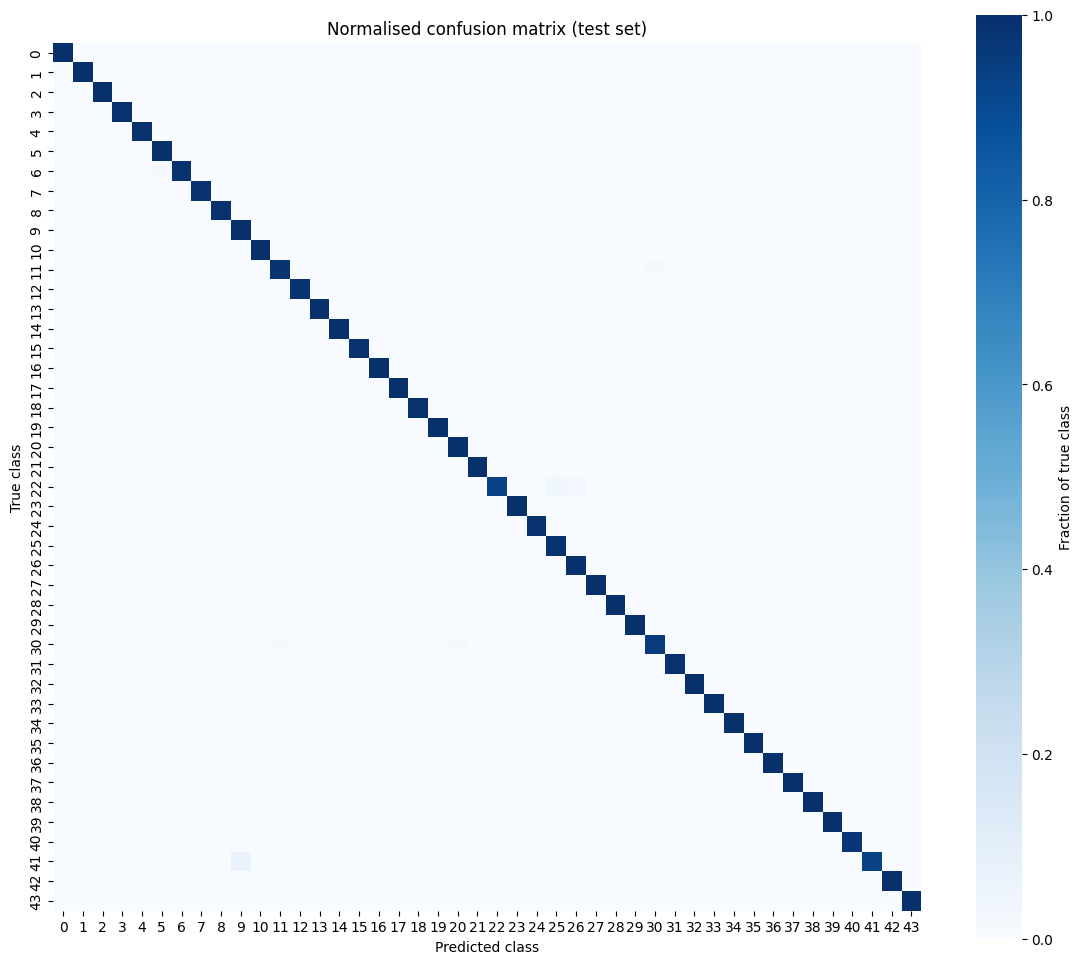

Top confusions (true → predicted):
    8×  [12] Priority road  →  [15] No vehicles
    7×  [11] Right-of-way at next intersection  →  [30] Beware of ice/snow
    5×  [22] Bumpy road  →  [25] Road work
    4×  [41] End of no passing  →  [9] No passing
    3×  [22] Bumpy road  →  [26] Traffic signals
    3×  [8] Speed limit (120km/h)  →  [5] Speed limit (80km/h)
    2×  [30] Beware of ice/snow  →  [20] Dangerous curve right
    2×  [25] Road work  →  [26] Traffic signals


In [ ]:
cm = confusion_matrix(full_test_labels, test_preds, labels=list(range(NUM_CLASSES)))
cm_norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
plt.figure(figsize=(14, 12))
sns.heatmap(cm_norm, cmap="Blues", xticklabels=range(NUM_CLASSES), yticklabels=range(NUM_CLASSES), square=True,
            cbar_kws={"label": "Fraction of true class"})
plt.xlabel("Predicted class"); plt.ylabel("True class"); plt.title("Normalised confusion matrix (test set)")
plt.show()

# Most frequent confusions
off = cm.copy(); np.fill_diagonal(off, 0)
top = np.dstack(np.unravel_index(np.argsort(-off.ravel())[:8], off.shape))[0]
print("Top confusions (true → predicted):")
for t, p in top:
    if off[t, p] > 0:
        print(f"  {off[t,p]:3d}×  [{t}] {CLASS_NAMES[t]}  →  [{p}] {CLASS_NAMES[p]}")

Misclassified: 72 of 13030


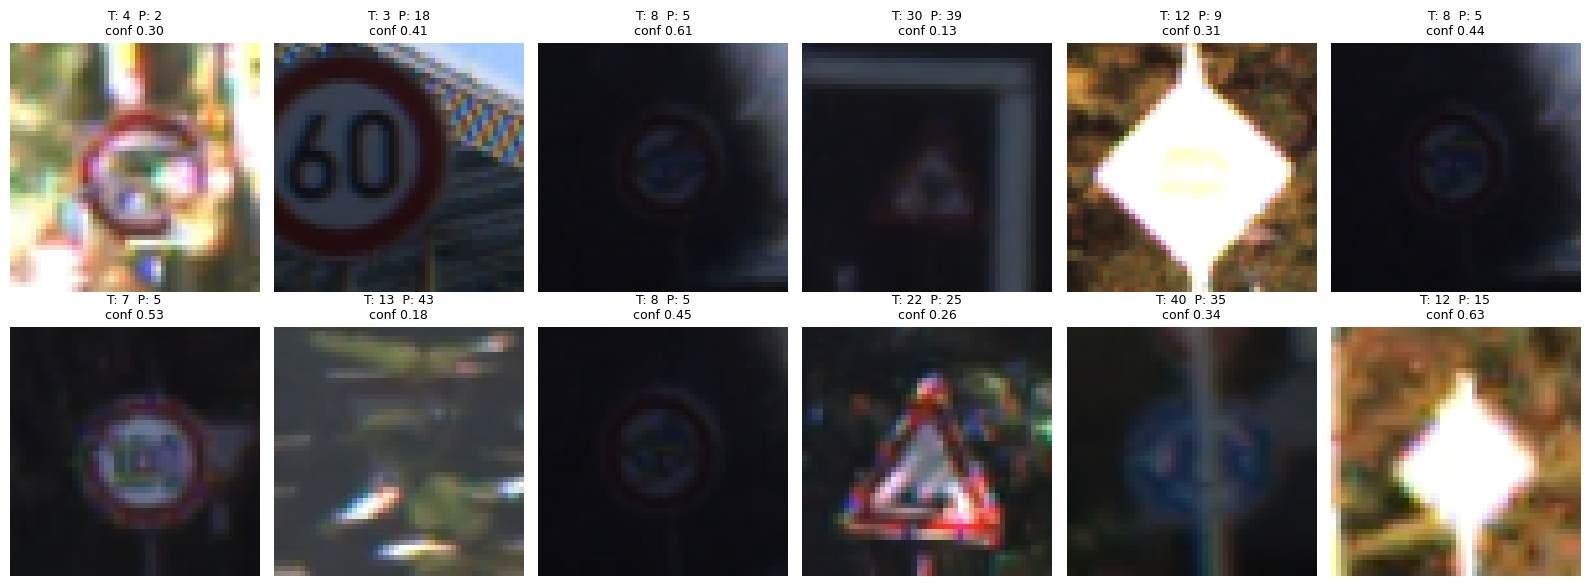

In [ ]:
# Misclassified examples
wrong = np.where(test_preds != full_test_labels)[0]
print(f"Misclassified: {len(wrong)} of {len(full_test_labels)}")
sel = np.random.choice(wrong, size=min(12, len(wrong)), replace=False)
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for ax, i in zip(axes.ravel(), sel):
    ax.imshow(full_test_imgs[i]); ax.axis("off")
    ax.set_title(f"T: {full_test_labels[i]}  P: {test_preds[i]}\nconf {test_probs[i].max():.2f}", fontsize=9)
plt.tight_layout(); plt.show()

## 8. Detection pipeline
For a full road image the detector runs these steps:

1. **HSV colour segmentation** – red (hue wraps around 0°/180° in OpenCV) and blue masks isolate sign borders and plates.
2. **Morphology** – closing joins the broken ring of a sign, opening removes speckle.
3. **Contours → candidate boxes** – filtered by size and aspect ratio (signs are roughly square), then padded by 8 %.
4. **Classification** – each crop is resized to 48×48 and passed through the CNN; crops predicted as *background* or with confidence below a threshold are discarded.
5. **NMS** – overlapping boxes are merged, keeping the most confident one.

In [ ]:
def propose_regions(img_rgb, min_side=24, max_side=300, pad_ratio=0.08):
    hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    red  = cv2.inRange(hsv, (0, 90, 60), (10, 255, 255)) | cv2.inRange(hsv, (170, 90, 60), (180, 255, 255))
    blue = cv2.inRange(hsv, (100, 120, 50), (130, 255, 255))
    mask = red | blue
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((7, 7), np.uint8))
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN,  np.ones((3, 3), np.uint8))
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    H, W = img_rgb.shape[:2]
    boxes = []
    for c in contours:
        x, y, w, h = cv2.boundingRect(c)
        if min_side <= w <= max_side and min_side <= h <= max_side and 0.6 <= w / h <= 1.6:
            pad = int(pad_ratio * max(w, h))
            boxes.append((max(0, x - pad), max(0, y - pad), min(W, x + w + pad), min(H, y + h + pad)))
    return boxes, mask

@torch.no_grad()
def classify_crops(img_rgb, boxes):
    if not boxes:
        return np.zeros((0, NUM_CLASSES))
    batch = []
    for (x0, y0, x1, y1) in boxes:
        crop = cv2.resize(img_rgb[y0:y1, x0:x1], (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
        batch.append(torch.from_numpy(crop).permute(2, 0, 1).float() / 255.0)
    x = (torch.stack(batch) - 0.5) / 0.5
    model.eval()
    return F.softmax(model(x.to(device)), dim=1).cpu().numpy()

def detect_signs(img_rgb, conf_thr=0.80, nms_iou=0.4):
    boxes, mask = propose_regions(img_rgb)
    probs = classify_crops(img_rgb, boxes)
    dets = []
    for b, p in zip(boxes, probs):
        c = int(p.argmax())
        if c != BG_CLASS and p[c] >= conf_thr:
            dets.append((b, c, float(p[c])))
    if dets:
        bt = torch.tensor([d[0] for d in dets], dtype=torch.float32)
        st = torch.tensor([d[2] for d in dets])
        dets = [dets[i] for i in nms(bt, st, nms_iou).tolist()]
    return dets, mask

def draw_detections(img_rgb, dets, gt_boxes=None):
    out = img_rgb.copy()
    if gt_boxes is not None:
        for (x0, y0, x1, y1) in gt_boxes:
            cv2.rectangle(out, (x0, y0), (x1, y1), (255, 255, 0), 1)
    for (x0, y0, x1, y1), c, s in dets:
        cv2.rectangle(out, (x0, y0), (x1, y1), (0, 220, 0), 2)
        label = f"{CLASS_NAMES[c][:24]} {s:.2f}"
        (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.5, 1)
        cv2.rectangle(out, (x0, max(0, y0 - th - 6)), (x0 + tw + 4, y0), (0, 220, 0), -1)
        cv2.putText(out, label, (x0 + 2, y0 - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 0), 1, cv2.LINE_AA)
    return out

## 9. Synthetic scene evaluation
`make_scene` pastes 1–3 random **test-set** signs (never seen during training) at random sizes (56–130 px) onto a cluttered 480×640 background, with slight brightness change and blur. The ground-truth boxes (yellow) are known exactly.

A detection is a **true positive** if its IoU with a ground-truth box is ≥ 0.5 *and* the predicted class matches.

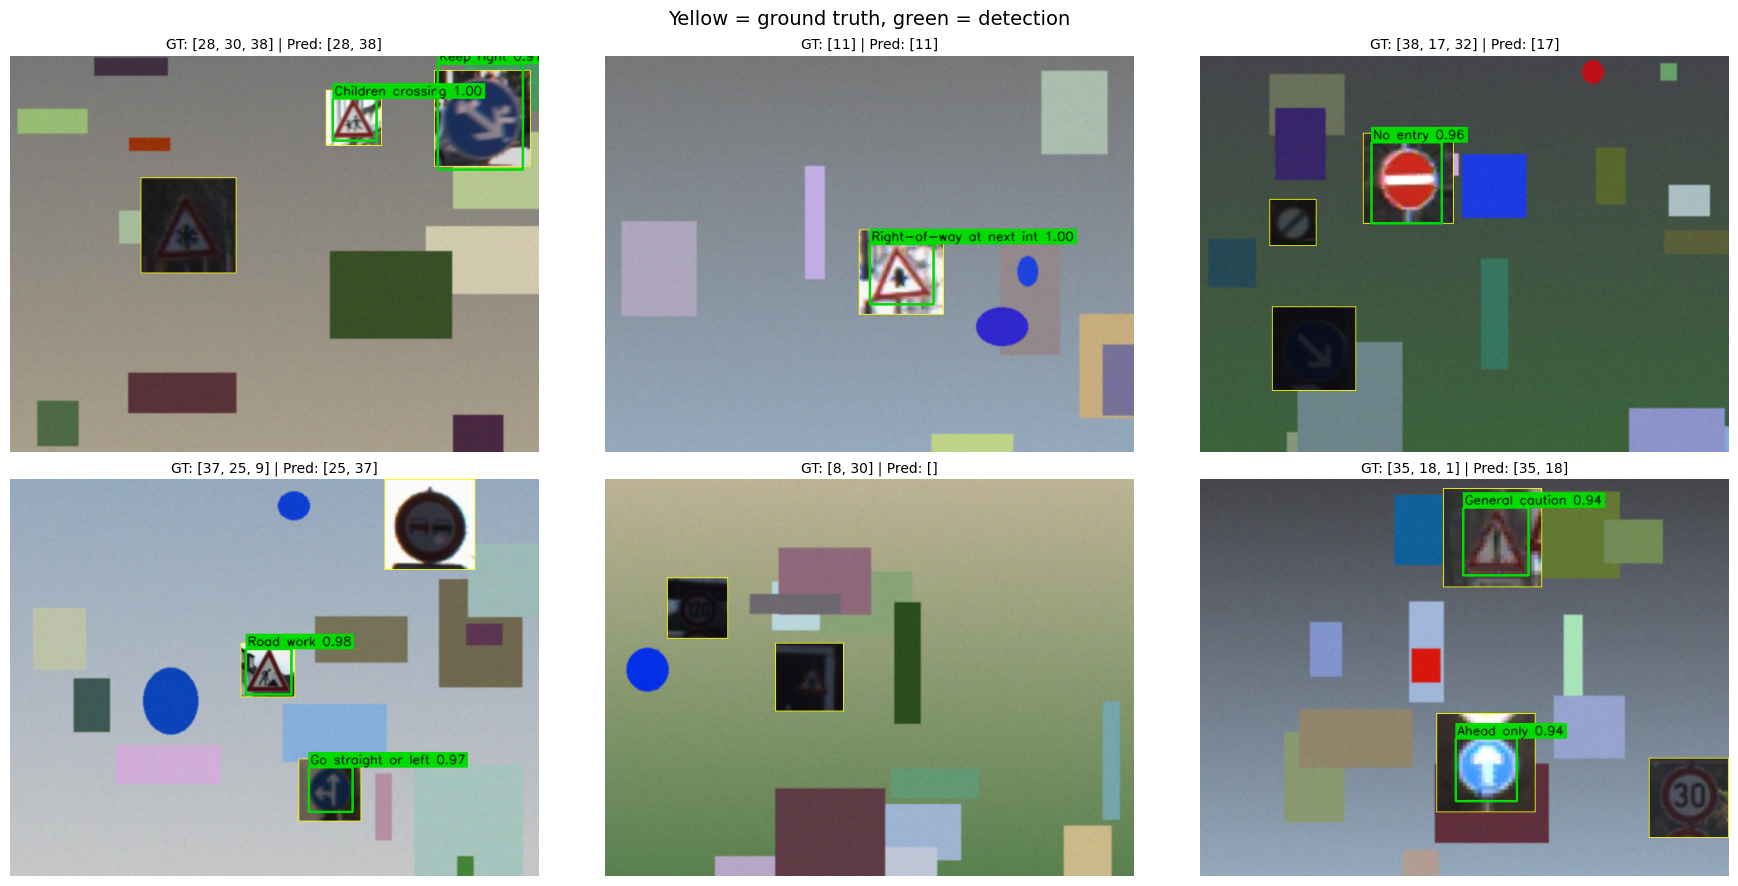

In [ ]:
def make_scene(rng, H=480, W=640, max_signs=3):
    scene = make_background(H, W, rng)
    gts, placed = [], []
    for _ in range(int(rng.integers(1, max_signs + 1))):
        for _try in range(20):
            s = int(rng.integers(56, 131))
            x, y = int(rng.integers(0, W - s)), int(rng.integers(0, H - s))
            box = (x, y, x + s, y + s)
            if all(max(0, min(box[2], b[2]) - max(box[0], b[0])) * max(0, min(box[3], b[3]) - max(box[1], b[1])) == 0
                   for b in placed):
                idx = int(rng.integers(len(raw_test)))
                img, label = raw_test[idx]
                sign = cv2.resize(np.array(img.convert("RGB")), (s, s), interpolation=cv2.INTER_AREA)
                sign = np.clip(sign.astype(np.float32) * rng.uniform(0.8, 1.15), 0, 255).astype(np.uint8)
                sign = cv2.GaussianBlur(sign, (3, 3), 0)
                scene[y:y + s, x:x + s] = sign
                placed.append(box); gts.append((box, int(label)))
                break
    return scene, gts

rng = np.random.default_rng(123)
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax in axes.ravel():
    scene, gts = make_scene(rng)
    dets, _ = detect_signs(scene)
    ax.imshow(draw_detections(scene, dets, [g[0] for g in gts])); ax.axis("off")
    ax.set_title(f"GT: {[g[1] for g in gts]} | Pred: {[d[1] for d in dets]}", fontsize=10)
plt.suptitle("Yellow = ground truth, green = detection", fontsize=14)
plt.tight_layout(); plt.show()

In [ ]:
def evaluate_detector(n_scenes=200, iou_thr=0.5, conf_thr=0.80, seed=999):
    rng = np.random.default_rng(seed)
    tp = fp = fn = 0
    loc_hits = 0; total_gt = 0
    for _ in range(n_scenes):
        scene, gts = make_scene(rng)
        dets, _ = detect_signs(scene, conf_thr=conf_thr)
        total_gt += len(gts)
        used = set()
        gt_t = torch.tensor([g[0] for g in gts], dtype=torch.float32)
        for gi, (gbox, glabel) in enumerate(gts):
            matched = False
            for di, (dbox, dcls, dsc) in enumerate(dets):
                iou = box_iou(gt_t[gi:gi+1], torch.tensor([dbox], dtype=torch.float32)).item()
                if iou >= iou_thr:
                    loc_hits += 1
                    if dcls == glabel and di not in used:
                        matched = True; used.add(di); break
            tp += matched; fn += (not matched)
        fp += len(dets) - len(used)
    precision = tp / max(tp + fp, 1); recall = tp / max(tp + fn, 1)
    f1 = 2 * precision * recall / max(precision + recall, 1e-9)
    print(f"Scenes: {n_scenes} | Ground-truth signs: {total_gt}")
    print(f"Localisation recall (IoU≥{iou_thr}, any class): {loc_hits/total_gt*100:.1f}%")
    print(f"TP {tp} | FP {fp} | FN {fn}")
    print(f"Precision {precision*100:.1f}% | Recall {recall*100:.1f}% | F1 {f1*100:.1f}%")
    return precision, recall

_ = evaluate_detector()

Scenes: 200 | Ground-truth signs: 412
Localisation recall (IoU≥0.5, any class): 35.7%
TP 147 | FP 21 | FN 265
Precision 87.5% | Recall 35.7% | F1 50.7%



--- conf_thr = 0.5 ---
Scenes: 100 | Ground-truth signs: 197
Localisation recall (IoU≥0.5, any class): 39.1%
TP 77 | FP 15 | FN 120
Precision 83.7% | Recall 39.1% | F1 53.3%

--- conf_thr = 0.6 ---
Scenes: 100 | Ground-truth signs: 197
Localisation recall (IoU≥0.5, any class): 38.6%
TP 76 | FP 15 | FN 121
Precision 83.5% | Recall 38.6% | F1 52.8%

--- conf_thr = 0.7 ---
Scenes: 100 | Ground-truth signs: 197
Localisation recall (IoU≥0.5, any class): 37.6%
TP 74 | FP 15 | FN 123
Precision 83.1% | Recall 37.6% | F1 51.7%

--- conf_thr = 0.8 ---
Scenes: 100 | Ground-truth signs: 197
Localisation recall (IoU≥0.5, any class): 36.5%
TP 72 | FP 12 | FN 125
Precision 85.7% | Recall 36.5% | F1 51.2%

--- conf_thr = 0.9 ---
Scenes: 100 | Ground-truth signs: 197
Localisation recall (IoU≥0.5, any class): 34.0%
TP 67 | FP 8 | FN 130
Precision 89.3% | Recall 34.0% | F1 49.3%

--- conf_thr = 0.95 ---
Scenes: 100 | Ground-truth signs: 197
Localisation recall (IoU≥0.5, any class): 27.9%
TP 55 | FP 6 | 

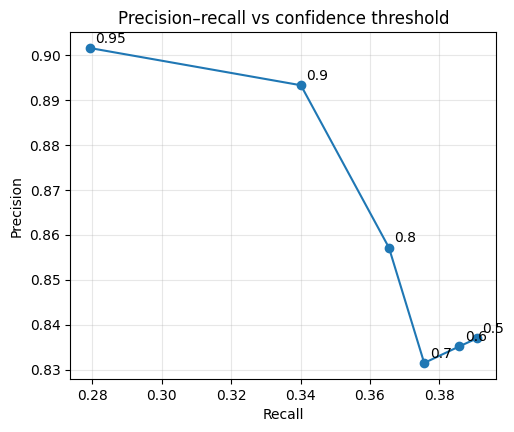

In [ ]:
# Effect of the confidence threshold (precision–recall trade-off)
thrs = [0.5, 0.6, 0.7, 0.8, 0.9, 0.95]
P, R = [], []
for t in thrs:
    print(f"\n--- conf_thr = {t} ---")
    p, r = evaluate_detector(n_scenes=100, conf_thr=t)
    P.append(p); R.append(r)
plt.figure(figsize=(5.5, 4.5))
plt.plot(R, P, "o-")
for t, r, p in zip(thrs, R, P): plt.annotate(str(t), (r, p), textcoords="offset points", xytext=(4, 4))
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Precision–recall vs confidence threshold"); plt.grid(alpha=.3)
plt.show()

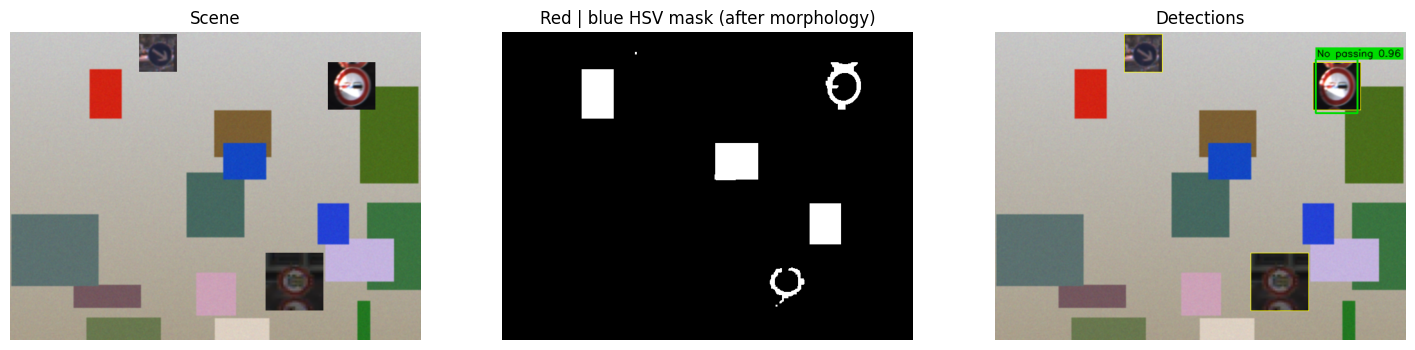

In [ ]:
# Debug view: what does the colour segmentation see?
scene, gts = make_scene(np.random.default_rng(7))
dets, mask = detect_signs(scene)
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].imshow(scene); ax[0].set_title("Scene")
ax[1].imshow(mask, cmap="gray"); ax[1].set_title("Red | blue HSV mask (after morphology)")
ax[2].imshow(draw_detections(scene, dets, [g[0] for g in gts])); ax[2].set_title("Detections")
for a in ax: a.axis("off")
plt.show()

## 10. Try it on your own image
Upload a street photo (JPG/PNG) containing traffic signs. Real photos are harder than the synthetic scenes (lighting, perspective, occlusion), so try lowering `conf_thr` to 0.6–0.7 if nothing is detected.

Saving HTS-header-street-name-signs-1800x1800_3024x.jpg to HTS-header-street-name-signs-1800x1800_3024x.jpg


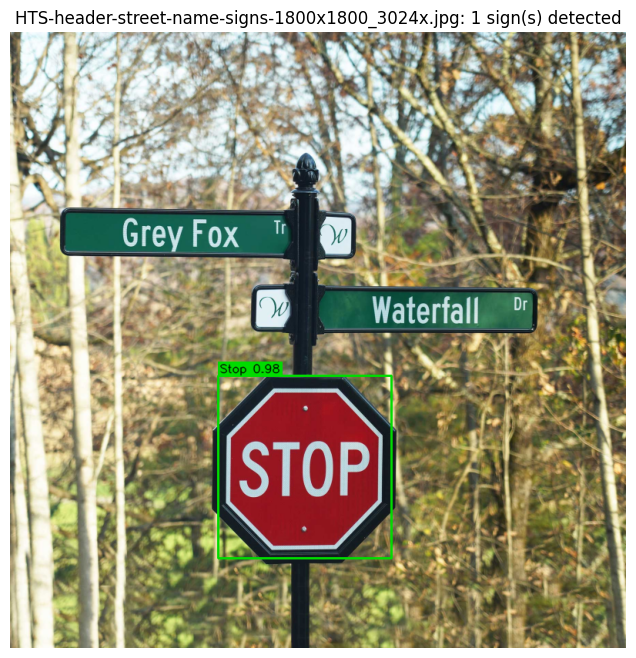

  Stop                                     conf 0.98 box (270, 446, 495, 683)


In [ ]:
from google.colab import files

uploaded = files.upload()
for name in uploaded:
    bgr = cv2.imread(name)
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    scale = 800 / max(rgb.shape[:2])                 # keep the longest side near 800 px
    if scale < 1: rgb = cv2.resize(rgb, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    dets, mask = detect_signs(rgb, conf_thr=0.70)
    plt.figure(figsize=(12, 8)); plt.imshow(draw_detections(rgb, dets)); plt.axis("off")
    plt.title(f"{name}: {len(dets)} sign(s) detected"); plt.show()
    for box, c, s in dets:
        print(f"  {CLASS_NAMES[c]:<40s} conf {s:.2f} box {box}")

## 12. Limitations and possible extensions

**Limitations**
* Colour-based proposals fail for faded signs, strong shadows, night scenes and sign types without red/blue borders (e.g. yellow *priority road* diamonds are only found through their red/blue-free parts and may be missed).
* The synthetic scenes are easier than real driving footage; expect lower recall on dashcam images.
* GTSRB is a German dataset; signs from other countries will be misclassified.
* The background class only knows the synthetic distractors it was trained on.

**Extensions**
1. **End-to-end detector:** fine-tune **YOLOv8** (`pip install ultralytics`) on a bounding-box dataset such as GTSDB (German Traffic Sign *Detection* Benchmark) or a Roboflow/Kaggle traffic-sign set, then compare mAP@0.5 with this pipeline.
2. Replace the HSV proposals with **MSER / Selective Search** or a lightweight region-proposal network.
3. Use transfer learning (MobileNetV3, EfficientNet-B0) for higher accuracy, then export to TFLite/ONNX for edge devices.
4. Add hard-negative mining: collect false positives from real videos and add them to the background class.
5. Add temporal smoothing (tracking) for video streams.

**References**
* Stallkamp et al., *Man vs. computer: Benchmarking machine learning algorithms for traffic sign recognition*, Neural Networks, 2012 (GTSRB).
* Houben et al., *Detection of Traffic Signs in Real-World Images: The German Traffic Sign Detection Benchmark*, IJCNN 2013 (GTSDB).